# From pipe priorities to a replacement plan
Builds a practical baseline: choose circles, order them using the priority scores, and estimate when they can be executed.

We calculate a **no-future-leak replacement budget**. This is conservative for replacement expenditure because future leak repairs convert pipes to polyurethane and can only reduce later replacement costs. It does not bound leak repair losses or guarantee a good competition score. We do not know the future leak outcomes.

In [1]:
from pathlib import Path
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

project_folder = Path.cwd()
if project_folder.name == "notebooks":
    project_folder = project_folder.parent
raw_folder = project_folder / "data" / "raw"
output_folder = project_folder / "data" / "processed"
output_folder.mkdir(parents=True, exist_ok=True)

pipes = pd.read_csv(raw_folder / "pipes.csv")
leaks = pd.read_csv(raw_folder / "train.csv")
priorities = pd.read_csv(output_folder / "pipe_priority_2027.csv")
assert pipes["Pipe ID"].is_unique
assert priorities["Pipe ID"].is_unique
pipes["Material"] = pipes["Material"].fillna("unknown")
pipes["length_m"] = np.hypot(pipes["GPS x2"] - pipes["GPS x1"],
                             pipes["GPS y2"] - pipes["GPS y1"])
pipes = pipes.merge(priorities[["Pipe ID", "priority_score"]], on="Pipe ID", how="left")
pipes["priority_score"] = pipes["priority_score"].fillna(0)

already_poly = pipes["Material"].eq("polyurethane") | pipes["Pipe ID"].isin(leaks["Pipe ID"])
iron = pipes["Material"].isin(["cast iron", "wrought iron", "gray iron"])
unknown = pipes["Material"].eq("unknown")
# Include unknown material pipes as conservative coverage targets.
target = ((iron | unknown) & ~already_poly).to_numpy()
initial_active = (~already_poly).to_numpy()
assert pipes.loc[initial_active, "Pipe ID"].isin(priorities["Pipe ID"]).all(), "Run the priority notebook on these same inputs."
print("Known iron targets:", int((iron.to_numpy() & target).sum()))
print("Unknown material targets:", int((unknown.to_numpy() & target).sum()))

Known iron targets: 26237
Unknown material targets: 8


## Corrected project formula
Cost = 100 + surface rate × area^0.85 + 200 × replacement length. The exponent applies to area only, following the corrected project instructions.

## 1. Find pipes fully inside a circle
For straight segments, both endpoints must be inside. Midpoints alone do not establish coverage.

The spatial tree narrows the search; the endpoint check decides coverage. All pipes remain in the search, including polyurethane pipes, because their surfaces affect excavation cost.

In [2]:
x1 = pipes["GPS x1"].to_numpy()
y1 = pipes["GPS y1"].to_numpy()
x2 = pipes["GPS x2"].to_numpy()
y2 = pipes["GPS y2"].to_numpy()
mid_x = (x1 + x2) / 2
mid_y = (y1 + y2) / 2
half_length = pipes["length_m"].to_numpy() / 2
lengths = pipes["length_m"].to_numpy()
scores = pipes["priority_score"].to_numpy()
tree = cKDTree(np.column_stack([mid_x, mid_y]))

surface_prices = {"grassland": 3, "farmland": 7, "swamp": 12,
                  "road": 17, "structure": 50, "water": 32}
assert pipes["Surface"].isin(surface_prices).all()
surfaces = pipes["Surface"].to_numpy()

def pipes_in_circle(x, y, radius):
    nearby = np.array(tree.query_ball_point([x, y], radius), dtype=int)
    first_inside = (x1[nearby] - x)**2 + (y1[nearby] - y)**2 <= radius**2
    second_inside = (x2[nearby] - x)**2 + (y2[nearby] - y)**2 <= radius**2
    return nearby[first_inside & second_inside]

def circle_cost(radius, inside, active):
    replacing = inside[active[inside]]
    if len(replacing) == 0:
        return 0
    # Each surface rate appears once, even if many pipes have that surface.
    surface_rate = sum(surface_prices[s] for s in np.unique(surfaces[inside]))
    area = np.pi * radius**2
    cost = 100 + surface_rate * area**0.85 + 200 * lengths[replacing].sum()
    return int(round(cost * 100))  # cents, to avoid accumulated float errors

# Small geometry check: a seed's own circle must contain the whole seed.
seed = np.flatnonzero(target)[0]
radius = half_length[seed] + 0.001
assert seed in pipes_in_circle(mid_x[seed], mid_y[seed], radius)
print("Circle geometry check passed")

Circle geometry check passed


## 2. Build circles around the targets
Start with high-priority targets. For each uncovered target, compare its own enclosing circle with a few larger circles at the same centre. Choose the lowest estimated cost per newly covered target.

This is a greedy heuristic, not a globally optimal solution. Copper and brass inside the chosen circle are automatically included in replacement costs. Nearby circles may overlap.

In [3]:
def build_circles(extra_radii):
    uncovered = target.copy()
    active = initial_active.copy()
    chosen = []
    seed_order = np.argsort(-scores, kind="stable")

    for seed in seed_order:
        if not uncovered[seed]:
            continue
        x, y = mid_x[seed], mid_y[seed]
        own_radius = half_length[seed] + 0.001
        radii = sorted(set([own_radius] + [max(own_radius, r) for r in extra_radii]))
        best = None
        for radius in radii:
            inside = pipes_in_circle(x, y, radius)
            new_targets = inside[uncovered[inside]]
            if len(new_targets) == 0:
                continue
            cost = circle_cost(radius, inside, active)
            cost_per_target = cost / len(new_targets)
            if best is None or cost_per_target < best[0]:
                best = (cost_per_target, radius, inside)
        _, radius, inside = best
        chosen.append({"x": x, "y": y, "radius": radius, "inside": inside})
        uncovered[inside] = False
        active[inside] = False

    assert not uncovered.any()
    return chosen

# Compare seed-sized circles with a grouped-circle option.
single_circles = build_circles([])
grouped_circles = build_circles([15, 25, 40, 60])
print("Seed-sized circles:", len(single_circles))
print("Grouped circles:", len(grouped_circles))

Seed-sized circles: 22058
Grouped circles: 12077


## 3. Order the circles and apply the annual budget
Order circles by estimated leak cost protected per replacement dollar. This is a fixed initial ordering; overlap and future risk are not re-optimized after each circle.

Recalculate costs in that final order so overlapping pipes are charged for replacement only once. The next circle must wait if it is unaffordable; we do not skip ahead. Unused funds carry forward. Funding is added at the start of each year, from 2027 to 2051 inclusive.

In [4]:
def schedule_circles(circles):
    def ordering_score(circle):
        inside = circle["inside"]
        protected_score = scores[inside[initial_active[inside]]].sum()
        estimated_cents = circle_cost(circle["radius"], inside, initial_active)
        return protected_score / max(estimated_cents / 100, 1)

    ordered = sorted(circles, key=ordering_score, reverse=True)
    active = initial_active.copy()
    covered = np.zeros(len(pipes), dtype=bool)
    annual_cents = 10_000_000 * 100
    budget = annual_cents
    year = 2027
    rows = []

    for number, circle in enumerate(ordered, start=1):
        inside = circle["inside"]
        cost = circle_cost(circle["radius"], inside, active)
        while cost > budget and year < 2051:
            year += 1
            budget += annual_cents
        if cost > budget:
            return None
        new_pipes = inside[active[inside]]
        rows.append({"work_unit": number, "x": circle["x"], "y": circle["y"],
                     "radius": circle["radius"], "year": year,
                     "cost": cost / 100, "new_pipes": len(new_pipes),
                     "new_targets": int(target[new_pipes].sum()),
                     "protected_priority": float(scores[new_pipes].sum())})
        budget -= cost
        covered[inside] = True
        active[inside] = False

    assert covered[target].all()
    assert not active[target].any()
    return pd.DataFrame(rows)

plans = {"Seed-sized": schedule_circles(single_circles),
         "Grouped": schedule_circles(grouped_circles)}
summary_rows = []
for name, plan in plans.items():
    summary_rows.append({"strategy": name, "feasible": plan is not None,
        "work_units": len(plan) if plan is not None else np.nan,
        "replacement_cost": plan["cost"].sum() if plan is not None else np.nan,
        "finish_year": plan["year"].max() if plan is not None else np.nan})
summary = pd.DataFrame(summary_rows)
print(summary.to_string(index=False))

feasible = summary[summary["feasible"]]
assert len(feasible) > 0, "Neither plan fits: try different grouping sizes."
# Choose lower replacement cost among feasible options. This does not optimize leak losses.
best_name = feasible.sort_values("replacement_cost").iloc[0]["strategy"]
plan = plans[best_name]
print("Selected:", best_name)
print("Replacement surplus before future leak costs:", round(250_000_000 - plan["cost"].sum(), 2))

  strategy  feasible  work_units  replacement_cost  finish_year
Seed-sized      True       22058      187733311.63         2045
   Grouped      True       12077      217318260.57         2048
Selected: Seed-sized
Replacement surplus before future leak costs: 62266688.37


## 4. Independently check the exported geometry and budget
Coordinates are written with 12 decimal places. Recheck those rounded values to ensure no endpoint falls outside an exported circle. Validate the budget again with integer cents.

In [5]:
plan[["x", "y", "radius"]] = plan[["x", "y", "radius"]].round(12)
covered = np.zeros(len(pipes), dtype=bool)
active = initial_active.copy()
budget = 0
current_year = 2026
verified_costs = []
for row in plan.itertuples(index=False):
    while current_year < row.year:
        current_year += 1
        budget += 10_000_000 * 100
    inside = pipes_in_circle(row.x, row.y, row.radius)
    cost = circle_cost(row.radius, inside, active)
    assert budget >= cost
    assert cost == int(round(row.cost * 100))
    budget -= cost
    active[inside] = False
    covered[inside] = True
    verified_costs.append(cost)
assert covered[target].all()
assert not active[target].any()
assert plan["year"].max() <= 2051
assert sum(verified_costs) <= 250_000_000 * 100
print("PASS: all known iron and unknown-material targets covered")
print("PASS: costs and annual budget checked in final order")

annual_summary = plan.groupby("year").agg(
    work_units=("work_unit", "count"), replacement_cost=("cost", "sum"),
    new_targets=("new_targets", "sum")
).reindex(range(2027, 2052), fill_value=0)
annual_summary["cumulative_cost"] = annual_summary["replacement_cost"].cumsum()
annual_summary["cumulative_funding"] = np.arange(1, 26) * 10_000_000
annual_summary["balance"] = annual_summary["cumulative_funding"] - annual_summary["cumulative_cost"]
assert annual_summary["balance"].ge(-0.01).all()
print(annual_summary.to_string())

PASS: all known iron and unknown-material targets covered
PASS: costs and annual budget checked in final order
      work_units  replacement_cost  new_targets  cumulative_cost  cumulative_funding      balance
year                                                                                             
2027        1754        9988304.51         2333     9.988305e+06            10000000     11695.49
2028        1160       10011505.21         1568     1.999981e+07            20000000       190.28
2029        2124        9983815.25         2657     2.998362e+07            30000000     16375.03
2030        2369       10004874.05         2968     3.998850e+07            40000000     11500.98
2031        2141       10010276.90         2497     4.999878e+07            50000000      1224.08
2032        2147        9989329.43         2414     5.998811e+07            60000000     11894.65
2033        1885       10010104.75         2203     6.999821e+07            70000000      1789.90
2034   

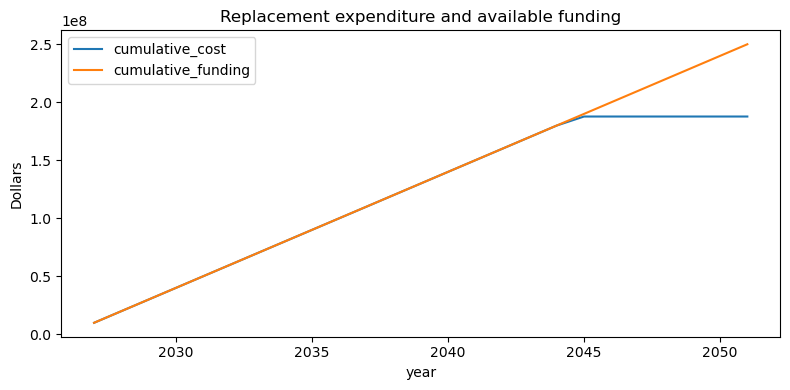

Saved plan, annual budget, comparison, and submission CSV to /Users/wendy/Desktop/STAT 440/STAT440_GP1/data/processed


In [6]:
annual_summary[["cumulative_cost", "cumulative_funding"]].plot(figsize=(8, 4))
plt.ylabel("Dollars")
plt.title("Replacement expenditure and available funding")
plt.tight_layout()
plt.show()

plan.to_csv(output_folder / "work_unit_plan.csv", index=False)
annual_summary.to_csv(output_folder / "annual_replacement_budget.csv")
summary.to_csv(output_folder / "circle_strategy_comparison.csv", index=False)

# Assignment format: no header, two fields per row, quoted centre then radius.
submission_path = output_folder / "work_units_submission.csv"
with open(submission_path, "w", newline="") as file:
    writer = csv.writer(file)
    for row in plan.itertuples(index=False):
        writer.writerow([f"({row.x:.12f}, {row.y:.12f})", f"{row.radius:.12f}"])
with open(submission_path, newline="") as file:
    exported_rows = list(csv.reader(file))
assert len(exported_rows) == len(plan)
assert all(len(row) == 2 for row in exported_rows)
print("Saved plan, annual budget, comparison, and submission CSV to", output_folder)

## How to interpret this baseline
- Cost calculations use all fully enclosed pipe surfaces and only currently non-polyurethane replacement lengths. Empty/polyurethane-only work units cost zero.
- Future leaks can reduce replacement expenditure and allow earlier execution. Their repair costs still reduce the score and are not included in this schedule.
- The one-year pipe priority score is a heuristic for ordering. Summing scores is not an estimate of total savings, especially over 25 years.
- The selected strategy minimizes replacement expenditure only among these two candidates. Compare alternatives using a leakage simulation or historical backtest before claiming the best competition score.
- The submission covers all remaining known iron plus eight unknown-material pipes, conservatively treated as targets. Unknown material treatment should be confirmed with the instructor.
- No maximum circle radius or count was specified in the supplied PDF. Our chosen radii are search settings, not assignment rules.